# [Lab Session 4](deconvolution.ipynb)

In [94]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.restoration import wiener
from scipy.signal import convolve2d as conv
from scipy.stats import multivariate_normal as multi_normal

np.random.seed(0)

Load the image.

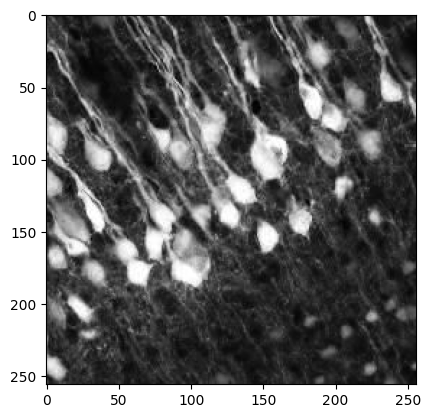

In [95]:
img = plt.imread('data/cells.png')[128:384, 128:384]
plt.imshow(img, 'gray')

**[Task 1.]()** Apply the following PSF to the image and then display it.

In [96]:
psf_size = 10
psf = np.ones((psf_size, psf_size)) / psf_size ** 2

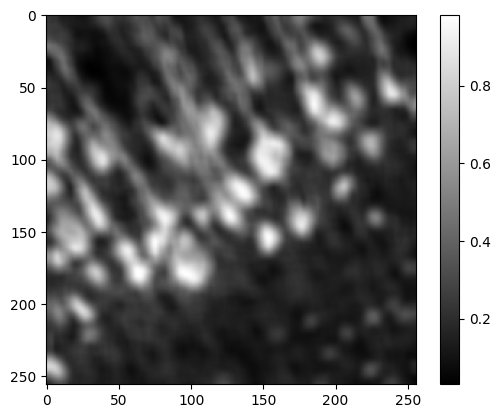

In [97]:
img_psf = conv(img, psf, mode='same', boundary='symm')

plt.figure()
plt.imshow(img_psf, 'gray')
plt.colorbar()


**[Task 2.]()** Have a look at the Gaussian PSF which is not uniformly distributed. Apply it to the image.

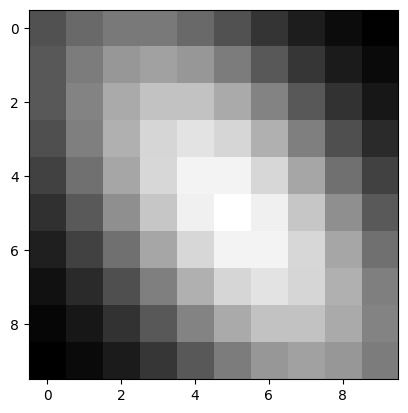

In [98]:
def create_psf(size):
    factor = size * 1.8
    x, y = np.mgrid[0:size:1, 0:size:1]
    pos = np.empty(x.shape + (2,))
    pos[:, :, 0] = x
    pos[:, :, 1] = y
    rv = multi_normal([int(size / 2), (int(size / 2))], [[factor * 1., factor * 1.2], [factor * .5, factor * .7]])
    return rv.pdf(pos)

plt.imshow(create_psf(psf_size), 'gray')

Apply the second psf to the image:

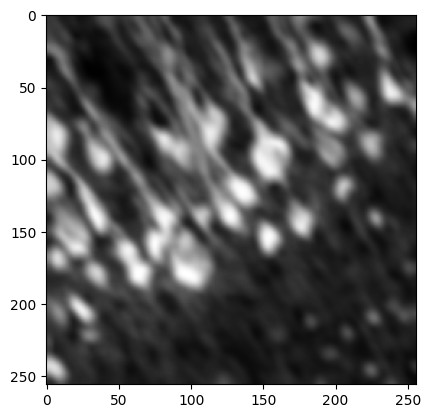

In [99]:
psf_gauss = create_psf(psf_size)


img_gpsf = conv(img, psf_gauss, mode='same', boundary='symm')

plt.figure()
plt.imshow(img_gpsf, 'gray')
plt.show()



**[Task 3.]()** Implement a reusable function that performs the Richardson-Lucy deconvolution.

In [106]:
def richardson_lucy_deconvolution(image, psf, n_iterations):
    img_deconv = np.full(image.shape, 0.5)
    
    psf_flipped = np.flip(psf)
    eps = 1e-12                                                  

    for t in range(n_iterations):
        estimate = conv(img_deconv, psf, mode='same', boundary='symm')  
        ratio = image / (estimate + eps)    
        img_deconv = img_deconv * conv(ratio, psf_flipped, mode='same', boundary='symm')
    
    img_deconv = img_deconv.clip(0,1)
    return img_deconv




**[Task 4.]()** Apply the Richardson-Lucy deconvolution to the blurred image.

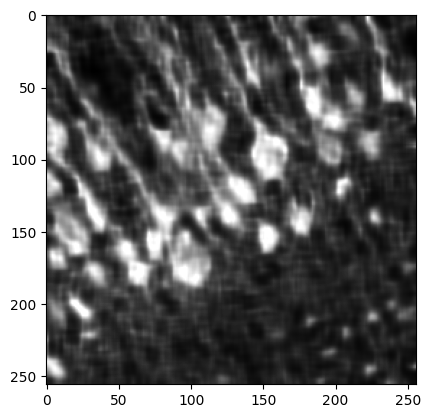

In [107]:
img_rld = richardson_lucy_deconvolution(img_psf,psf, 50 )

plt.imshow(img_rld, 'gray')

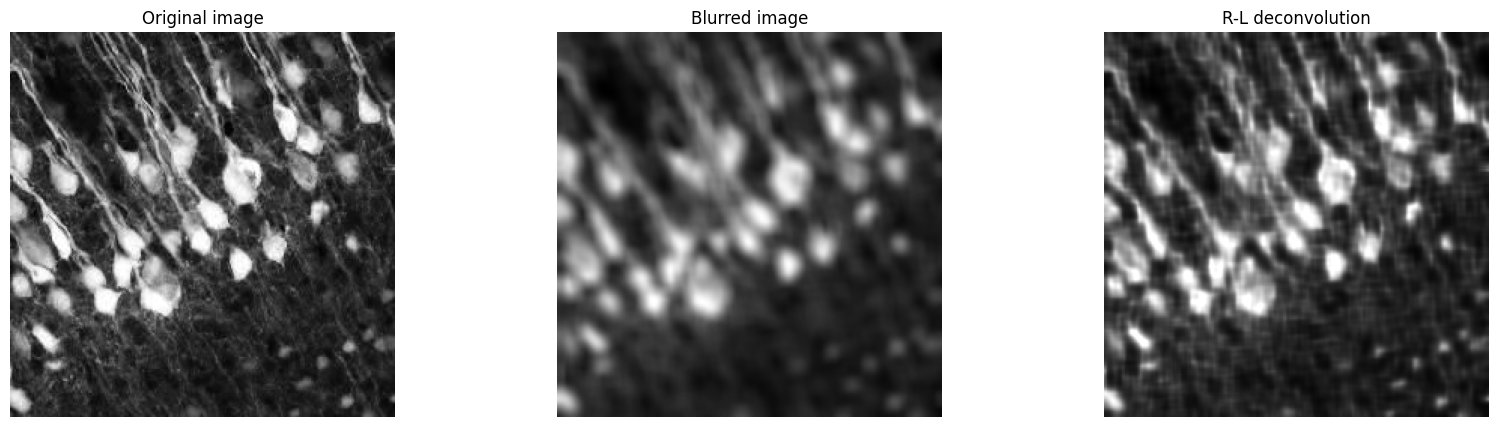

In [108]:
plt.figure(figsize=(20,5))
plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')
plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(img_psf, 'gray')
plt.title('Blurred image')
plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(img_rld, 'gray')
plt.title('R-L deconvolution')
plt.show()

**[Task 5.]()** Add noise to the image, use the R-L deconvolution again.

In [28]:
noise = (np.random.normal(loc=0,size=img.shape))
reduce_factor = 5
noise = noise / reduce_factor

In [35]:
img_n = (img_psf + noise)
img_nc = img_n.clip(0,1)

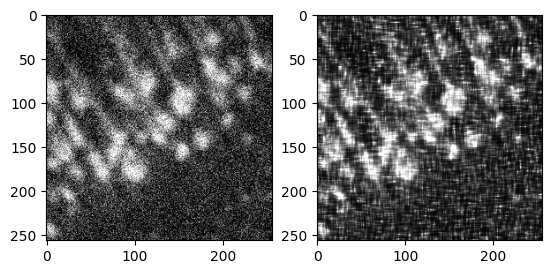

In [40]:


img_rn = richardson_lucy_deconvolution(img_nc, psf, 15)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow((img_nc), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(img_rn, 'gray')

**[Task 6.]()** Compare your R-L implementation to a wiener deconvolution.

Text(0.5, 1.0, 'Wiener 200')

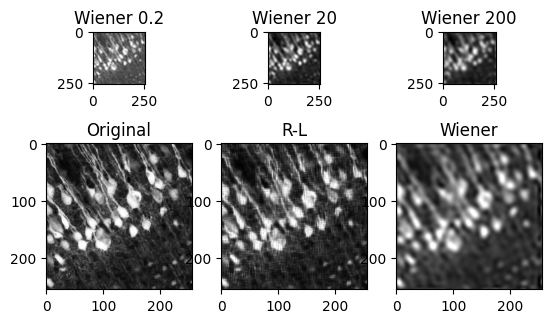

In [47]:
img_wn_02 = wiener(img_psf, psf, balance=0.2, clip=True)
img_wn = wiener(img_psf, psf, balance=2, clip=True)
img_wn_20 = wiener(img_psf, psf, balance=20, clip=True)
img_wn_200 = wiener(img_psf, psf, balance=200, clip=True)


plt.figure()
plt.subplot(1, 3, 1)
plt.imshow((img), 'gray')
plt.title('Original')
plt.subplot(1, 3, 2)
plt.imshow(img_rld, 'gray')
plt.title('R-L')
plt.subplot(1, 3, 3)
plt.imshow(img_wn, 'gray')
plt.title('Wiener')

plt.subplot(6, 3, 1)
plt.imshow(img_wn_02, 'gray')
plt.title('Wiener 0.2')
plt.subplot(6, 3, 2)
plt.imshow(img_wn_20, 'gray')
plt.title('Wiener 20')
plt.subplot(6, 3, 3)
plt.imshow(img_wn_200, 'gray')
plt.title('Wiener 200')

Text(0.5, 1.0, 'Wiener')

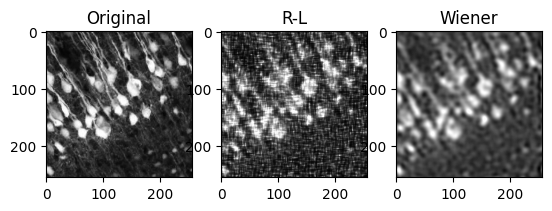

In [42]:
img_wnc = wiener(img_nc, psf, balance=2, clip=True)


plt.figure()
plt.subplot(1, 3, 1)
plt.imshow((img), 'gray')
plt.title('Original')
plt.subplot(1, 3, 2)
plt.imshow(img_rn, 'gray')
plt.title('R-L')
plt.subplot(1, 3, 3)
plt.imshow(img_wnc, 'gray')
plt.title('Wiener')

**[Task 7.]()** Repeat Tasks 4–6 using a smaller value for the size of the PSF.

Text(0.5, 1.0, 'Psf 100')

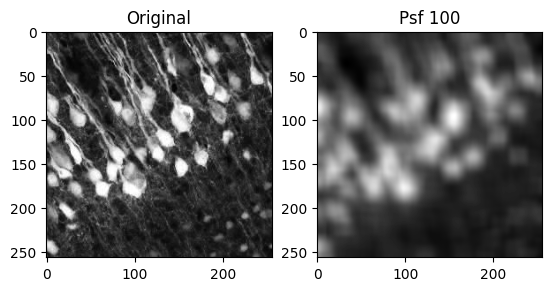

In [70]:
#psf_size
psf_size = 20
psf = np.ones((psf_size, psf_size)) / psf_size ** 2

#apply psf
img_psf_100 = conv(img, psf, mode='same', boundary='symm')

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow((img), 'gray')
plt.title('Original')
plt.subplot(1, 2, 2)
plt.imshow(img_psf_100, 'gray')
plt.title('Psf 100')






Text(0.5, 1.0, 'RLD 100')

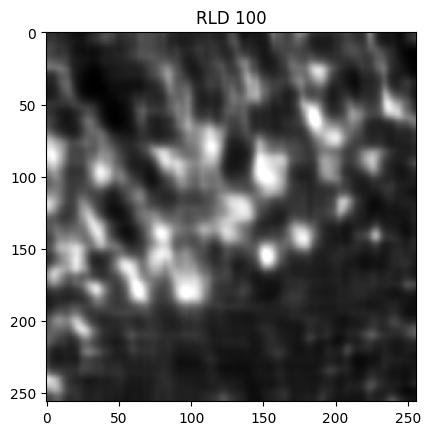

In [71]:
#task 4
img_rld_100 = richardson_lucy_deconvolution(img_psf_100,psf, 30 )

plt.figure()
plt.imshow((img_rld_100 ), 'gray')
plt.title('RLD 100')

Text(0.5, 1.0, 'RL on noise 100')

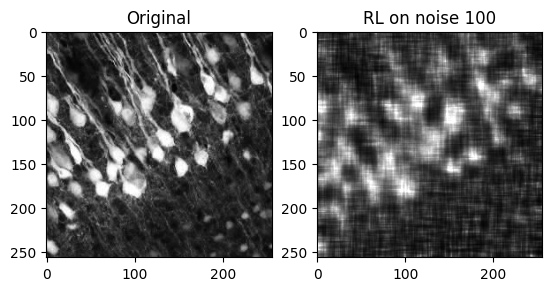

In [72]:
#task 5 
img_n_100 = (img_psf_100 + noise)
img_nc_100 = img_n_100.clip(0,1)

img_rn_100 = richardson_lucy_deconvolution(img_nc_100, psf, 15)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow((img), 'gray')
plt.title('Original')
plt.subplot(1, 2, 2)
plt.imshow(img_nc_100, 'gray')
plt.title('Noise 100')
plt.subplot(1, 2, 2)
plt.imshow(img_rn_100, 'gray')
plt.title('RL on noise 100')

Text(0.5, 1.0, 'Wiener')

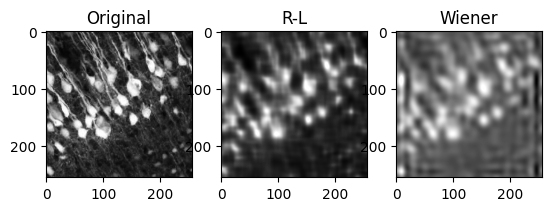

In [73]:
#task 6 
img_wn_100 = wiener(img_psf_100, psf, balance=2, clip=True)

plt.figure()
plt.subplot(1, 3, 1)
plt.imshow((img), 'gray')
plt.title('Original')
plt.subplot(1, 3, 2)
plt.imshow(img_rld_100, 'gray')
plt.title('R-L')
plt.subplot(1, 3, 3)
plt.imshow(img_wn_100, 'gray')
plt.title('Wiener')

**[Task 8.]()** Use a wrong PSF to restore the image

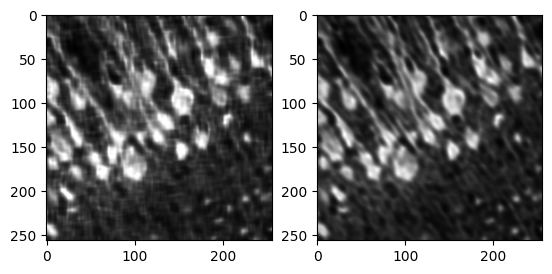

In [109]:


img_rlg = richardson_lucy_deconvolution(img_gpsf, psf_gauss, 30 )

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow((img_rld), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(img_rlg, 'gray')